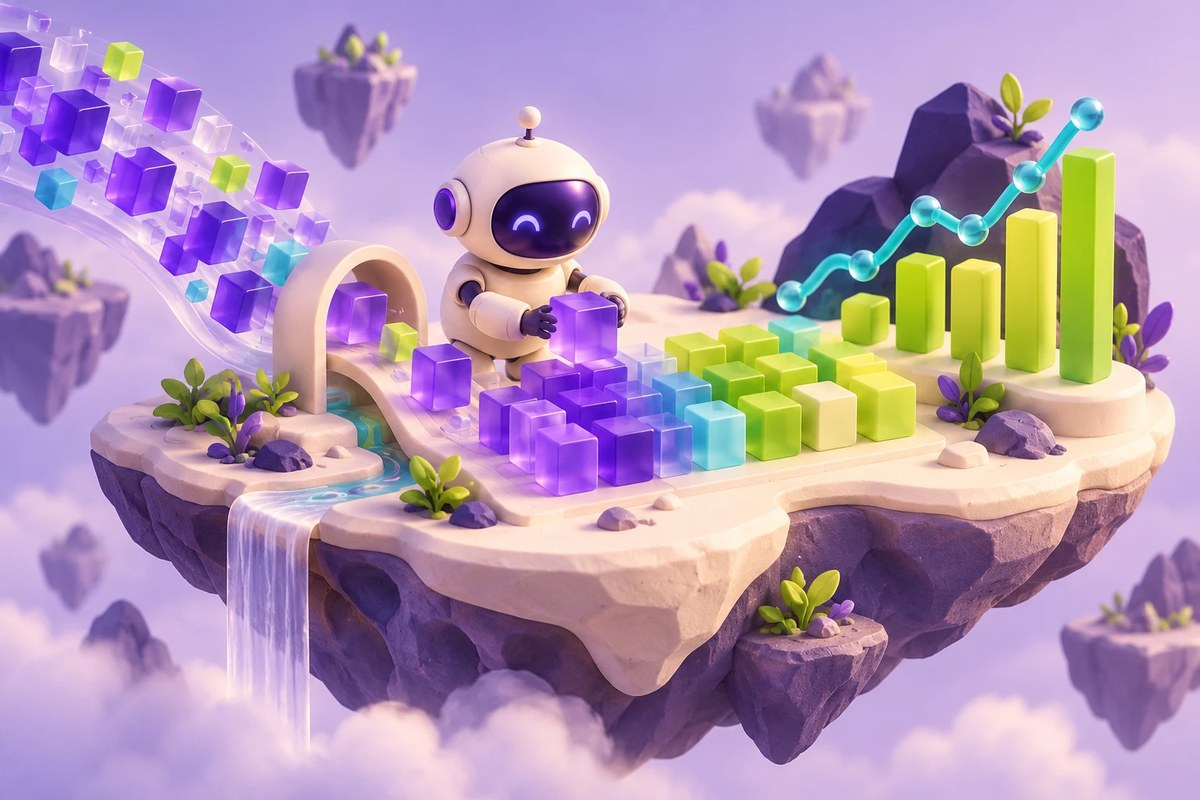

AI PATH · Python для машинного обучения · Урок 041

# Pandas: объединения, группы и время

От таблиц студентов до статистик Occupancy и дневных температур.

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-041-goal"></a>
## Что вы разберёте

Выбирать способ объединения и агрегации, проверяя ключи, типы и смысл временных интервалов.

### Перед началом

- DataFrame и индексация
- Среднее, медиана и квантили

### Что понадобится

- Pandas и NumPy
- wine_base.csv с country, points, price, region_1 и region_2
- datatraining.txt с date, Temperature и Occupancy; остальные признаки используются в статистиках

## Навигация по уроку

- [Цель и подготовка](#ai-041-goal)
- [Карта урока](#ai-041-map)
- [Входные таблицы](#ai-041-section-01)
- [Добавление и concat](#ai-041-section-02)
- [Группы](#ai-041-section-03)
- [Соединение по ключам](#ai-041-section-04)
- [Пропуски после join](#ai-041-section-05)
- [Временные выборки](#ai-041-section-06)
- [Статистики и преобразования](#ai-041-section-07)
- [Смена частоты](#ai-041-section-08)
- [Проверьте понимание](#ai-041-practice)
- [Источники и ограничения](#ai-041-provenance)

<a id="ai-041-map"></a>
## Карта урока

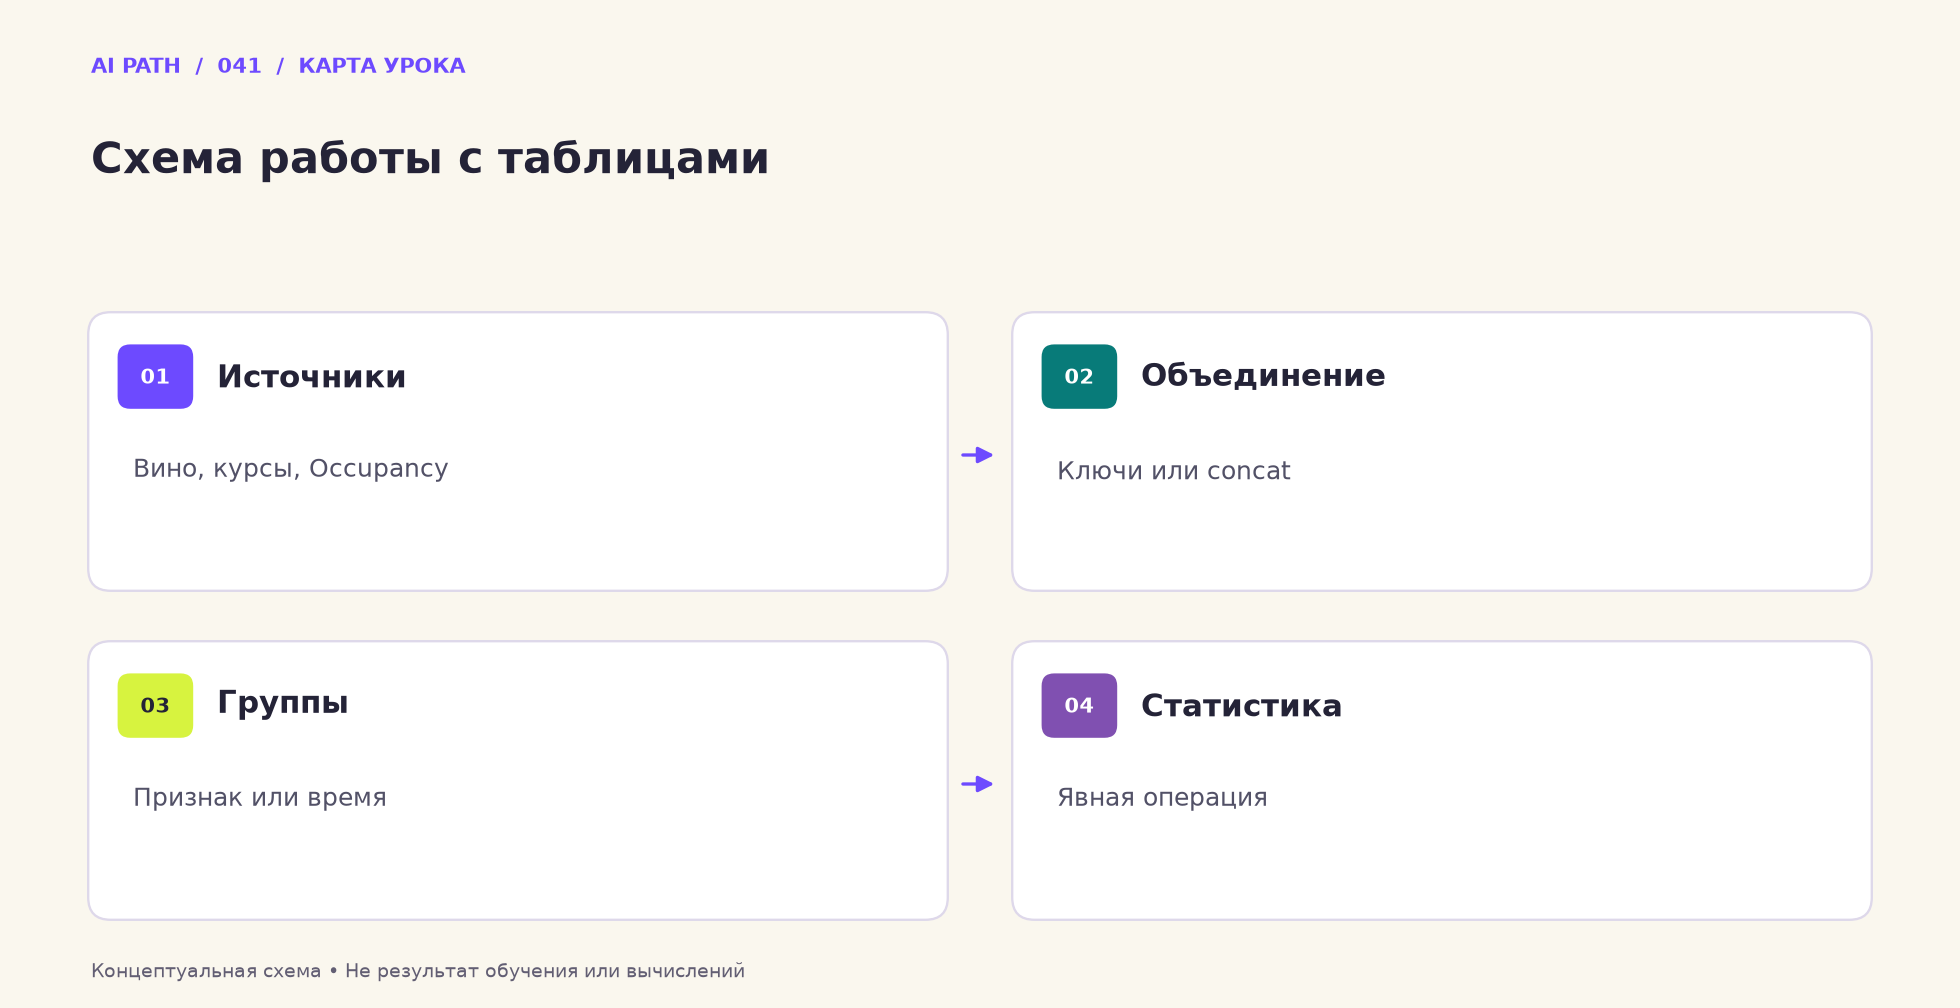

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Источники** — Вино, курсы, Occupancy
2. **Объединение** — Ключи или concat
3. **Группы** — Признак или время
4. **Статистика** — Явная операция

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%90%D0%BF%D1%80%D0%B5%D0%BB%D1%8C%D1%81%D0%BA%D0%B8%D0%B9_%D0%BA%D1%83%D1%80%D1%81_2020_Light_%D0%97%D0%B0%D0%BD%D1%8F%D1%82%D0%B8%D0%B5_4_Pandas_(%D1%87%D0%B0%D1%81%D1%82%D1%8C_2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a id="ai-041-section-01"></a>
## 01 · Входные таблицы

Проверьте структуру wine_base.csv и сохранённый индекс.

_Далее — исходные ячейки учебного материала._

## Pandas. Загрузка библиотек

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=213

In [0]:
import pandas as pd # Загружаем библиотеку Pandas
import numpy as np # Загружаем библиотеку numpy

In [0]:
data = pd.read_csv('wine_base.csv', index_col = 0) # С помощью метода read_csv загружаем файл wine_base.csv и записываем данные в data

<a id="ai-041-section-02"></a>
## 02 · Добавление и concat

Разделите объединение строк, создание столбца и независимое изменение копии.

_Далее — исходные ячейки учебного материала._

## 1. Конкатенация

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=938


In [0]:
a = [0, 1, 2, 3] # Создаем список а
b = [4, 5, 6, 7, 234, 23] # Создаем список b
b + a + b + a + a # Делаем конкатенацию (объединение) списков

[4, 5, 6, 7, 234, 23, 0, 1, 2, 3, 4, 5, 6, 7, 234, 23, 0, 1, 2, 3, 0, 1, 2, 3]

In [0]:
data_1 = data[0:15].copy() # Берем первые 15 строк из data и делаем их копию в data_1
data_2 = data[15:30].copy() # Берем строки с 15 по 30 из data и делаем их копию в data_2

In [0]:
data_2.head() # Выводим первые 5 строк data_2

In [0]:
df_concat = pd.concat([data_1, data_2]) # Объединяем два датафрейма
df_concat # Отображаем объединенный датафрейм

In [0]:
data_1.head() # Выводим первые 5 строк data_1

In [0]:
data_1.iloc[0,1] = 'Keras' # Изменяем значение в ячейке data_1
data_1.head(2) # Выводим на экран 2 первые строки data_1

In [0]:
df_concat.head(2)  # Выводим на экран 2 первые строки df_concat

## 2. Добавление столбцов и строк

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=1298

In [0]:
columns = ['A', 'B', 'C', 'D'] # Создаем список с названием столбцов
values = [[1,2,3,4], [5,6,7,8],[9,10,11,12], [13,14,15,16]] # Создаем список со значениями
df_for_add = pd.DataFrame(values, columns=columns) # Создаем датафрейм из сформированных значений
df_for_add # Выводим на экран датафрейм df_for_add

In [0]:
df_for_add['E'] = [17,18,19,20] # Добавляем столбец
df_for_add # Выводим на экран датафрейм df_for_add

In [0]:
df_for_add.loc[4] = [1,2,3,4,5] # Добавляем строку 
df_for_add # Выводим на экран датафрейм df_for_add

<a id="ai-041-section-03"></a>
## 03 · Группы

Среднее и максимум по стране требуют осмысленного выбора числовых признаков.

_Далее — исходные ячейки учебного материала._

## 3. Groupby

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=1492

In [0]:
data.head() # Выведем первые 5 строк data

Groupby - это очень важный и широко используемый метод. Позволяет делать группировку данных по какому-либо столбцу. 

Пример:
* посчитать средние баллы и цену в разрезе по странам и провинциям

In [0]:
df_mean = data.groupby(['country']).mean() # Группируем данные по странам и считаем среднее значение (считается для числовых столбцов)
df_mean.head() # Выводим первые 5 строк df_mean

In [0]:
df_max = data.groupby('country')[['points','price']].max() # Группируем данные по странам и считаем максимальное значение
df_max.head() # # Выводим первые 5 строк df_max

In [0]:
# сортировка по столбцу points
sorted_data = df_mean.sort_values('points', ascending=False) # Сортируем датафрейм со средними значениями по убыванию points
sorted_data.head(10) # Выводим первые 10 строк sorted_data

In [0]:
# группировка по трем столбцам
data.groupby(['country', 'region_1', 'region_2']).mean().head(10) # Выполняем группировку по трем столбцам (считаем среднее значение) и выводим первые 10 строк

<a id="ai-041-section-04"></a>
## 04 · Соединение по ключам

На маленьких таблицах студентов и курсов проследите left, right, inner и outer.

_Далее — исходные ячейки учебного материала._

## 4. Join

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=3398

Join - позволяет объединять несколько таблиц в единую по ключам (одинаковым столбцам). 

Join бывает разный:
*   Left
*   Right
*   Inner
*   FullJoin



Посмотрим на примерах, как это работает.

Допустим, у нас есть два датафрейма:
* первый содержит информацию о студентах и ID курсах, которые они посещают,
* второй - описание курсов.

In [0]:
# создаем первый датафрейм
data_1 = np.array([['100500', '200600', '100500', '300700', '200600', '500900'],
                   ['Анастасия', 'Екатерина', 'Светлана', 'Максим', 'Станислав', 'Данила'], 
                   ['Андреева', 'Петрова', 'Иванова', 'Егоров', 'Лесницкий', 'Кудряшев']])

names = pd.DataFrame(data_1.T, columns = ['subject_id', 'first_name', 'last_name']) # Создаем датафрейм из сформированных данных
names # Выводим датафрейм names на экран

In [0]:
# создаем второй датафрейм
data_2 = np.array([['100500', '200600', '300700', '400700'],
                   ['Математика', 'Программирование', 'Анализ данных', 'Мат. анализ'], 
                   ['продвинутые методы математической статистики', 'расширенный курс по с++',\
                            'краткий курс для чайников', 'многомерный анализ']])
subjects = pd.DataFrame(data_2.T, columns = ['subject_id','course_name', 'description']) # Создаем датафрейм из сформированных данных
subjects # Выводим датафрейм subjects на экран

#### Делаем Join:

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=3631

Left Join

In [0]:
names.merge(subjects, on='subject_id', how='left') # Объединяем два датафрейма по столбцу subject_id (join-left)

In [0]:
pd.merge(names, subjects, on='subject_id', how='right') # Объединяем два датафрейма по столбцу subject_id (join-right)

Inner Join

In [0]:
names.merge(subjects, on='subject_id', how='inner') # Объединяем два датафрейма по столбцу subject_id (join-inner)

Outer Join

In [0]:
df = names.merge(subjects, on='subject_id', how='outer') # Объединяем два датафрейма по столбцу subject_id (join-outer)
df

Join при разных названиях столбцов с ключом:

In [0]:
names_2 = names.copy() # Создаем копию датафрейма names
cols = names.columns.tolist() # Получаем список названий столбцов
cols[0] = 'ID' # Меняем название нулевого столбца на 'ID'
names_2.columns = cols # Присваиваем датафрейму names_2 новые названия столбцов
names_2 # Выводим на экран датафрейм names_2

In [0]:
# делаем join
pd.merge(names_2, subjects, left_on='ID', right_on='subject_id', how='inner') # Объединяем два датафрейма по столбцам ID и subject_id (join-inner)

Join по двум ключам:

In [0]:
cols_a = ['A', 'B', 'value_1'] # Создаем список названий колонок cols_a
cols_b = ['A', 'B', 'value_2'] # Создаем список названий колонок cols_b
data_a = [[1, 1, 23], [1, 2, 34], [2, 1, 2342], [2, 2, 333]] # Создаем список значение data_a
data_b = [[1, 1, 0.1], [1, 2, 0.2], [2, 2, 0.13], [2, 3, 0.33]] # Создаем список значение data_b
df_a = pd.DataFrame(data_a, columns=cols_a) # Формируем датафрейм df_a из созданных ранее данных
df_b = pd.DataFrame(data_b, columns=cols_b) # Формируем датафрейм df_b из созданных ранее данных

In [0]:
df_a # Выводим на экран датафрейм df_a

In [0]:
df_b # Выводим на экран датафрейм df_b

In [0]:
df_a.merge(df_b, on=['A', 'B'], how='outer') # Объединяем два датафрейма по столбцам A и B (join-outer)

А join по одному ключу в данном случае выглядел бы так:

In [0]:
df_a.merge(df_b, on='A', how='inner') # Объединяем два датафрейма по столбцу A (join-inner)

Или так:

In [0]:
df_a.merge(df_b, on='B', how='inner') # Объединяем два датафрейма по столбцу B (join-inner)

Или вот так по разным ключам:

In [0]:
pd.merge(df_a, df_b, left_on='A', right_on='B', how='inner') # Объединяем два датафрейма по столбцам A и B (join-inner)

<a id="ai-041-section-05"></a>
## 05 · Пропуски после join

Заполняйте пропуски по смыслу столбца, сохраняя возможность увидеть отсутствующее соответствие.

_Далее — исходные ячейки учебного материала._

Заполнение пропусков в одном из столбцов:

In [0]:
df # Выведем на экран датафрейм df

In [0]:
df.first_name = df.first_name.fillna('Не заполнено') # Заменяем пропуски в столбце first_name на значение 'Не заполнено'
df # Выводим на экран датафрейм df

In [0]:
df.last_name = df.last_name.fillna('Пропущено') # Заменяем пропуски в столбце last_name на значение 'Пропущено'
df # Выводим на экран датафрейм df

Во всей табличке:

In [0]:
df = df.fillna('Неизвестно') # Заменяем пропуски во всем датафрейме на значение 'Неизвестно'
df # Выводим на экран датафрейм df

Разными значениями в разных столбцах:

In [0]:
df = names.merge(subjects, on='subject_id', how='outer') # Объединяем два датафрейма по столбцу subject_id (join-outer)
df # Выводим на экран ДатаФрейм df

In [0]:
val = ['Не заполнено', 'Пропущено', 'Неизвестный курс', 'Неизвестное описание'] # Создаем список со значениями, которые будут использоваться вместо пропусков
cols = df.columns.tolist() # Получаем названия столбцов датафрейма df
cols.pop(0) # Удаляем 0 столбец  (соответствует subject_id)
print(cols) # Выводим на экран список cols

In [0]:
# создаем словарь с меппингом названий столбцов к значениям, какими нужно заполнить в них пропуски
dict_to_fill = dict(zip(cols, val)) # Создаем словарь, в котором в качестве ключей будут значения списка cols, а в качестве соответствующих значений - значения списка val
dict_to_fill # Выводим на экран словарь dict_to_fill

In [0]:
df = df.fillna(dict_to_fill) # Заменяем пропуски в соответствии со словарем dict_to_fill
df # Выводим на экран датафрейм df

<a id="ai-041-section-06"></a>
## 06 · Временные выборки

Преобразуйте date в индекс; различайте день месяца, день недели и час.

_Далее — исходные ячейки учебного материала._

## 5. DateTime index

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=4818

DateTime Index - это особый тип индекса в pandas, предназначенный для работы с временными рядами. Давайте познакомимся с ним поближе. Для этой цели мы подгрузим известный стандартный датасет "Occupancy Detection Data Set", он содержит следующие данные:
* дата и время замера
* температура в градусах по Цельсию
* относительная влажность в % 
* освещенность в Люксах
* CO2 в ppm 
* коэффициент влажности
* заполненность (1 - заполнено, 0 - не заполнено)

In [0]:
dataTraining = pd.read_csv('datatraining.txt') # Создаем датафрейм из файла datatraining.txt
dataTraining.head() # Отображаем первые 5 строк датафрейма dataTraining

Давайте превратим колонку с датой в datetime index:

In [0]:
dataTraining.index = pd.to_datetime(dataTraining.date) # Превращаем колонку date в индекс
dataTraining.head() # Отображаем первые 5 строк датафрейма dataTraining

In [0]:
dataTraining.drop('date', axis=1, inplace=True) # Удаляем колонку date из датафрейма
dataTraining.head() # Отображаем первые 5 строк датафрейма dataTraining

Давайте посмотрим, что можно делать с данными, имеющими временной индекс.

### 1. Подвыборки

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=5472

In [0]:
dataTraining.index # Выведем на экран колонку индексов

In [0]:
period = dataTraining[(dataTraining.index>'2015-02-04') & (dataTraining.index<='2015-02-07')] # Формируем новый датафрейм period, в который запишем все данные с 4 по 7 февраля 2015 года
period # Выведем на экран датафрейм period

In [0]:
month_set = dataTraining[dataTraining.index.month == 2] # Формируем новый датафрейм month_set, в который запишем все данные по февралю любого года
month_set # Выведем на экран датафрейм month_set

In [0]:
day_set = dataTraining[(dataTraining.index.day == 6) & (dataTraining.index.hour == 13)] # Формируем новый датафрейм day_set, в который запишем данные за все субботы в промежуток с 13-00 до 13-59
day_set # Выведем на экран датафрейм day_set

In [0]:
dataTraining['2015-02-06'] # Отобразим данные за 6 февраля 2015 года

In [0]:
dataTraining['2015-02-06':]  # Отобразим данные, начиная с 6 февраля 2015 года

In [0]:
dataTraining['2015-02-08 14:55':'2015-02-08 14:56']  # Отобразим данные, начиная с 14:55 и до 14:56 8 февраля 2015 года

<a id="ai-041-section-07"></a>
## 07 · Статистики и преобразования

Корреляция, квантили, накопления и стандартизация отвечают на разные вопросы.

_Далее — исходные ячейки учебного материала._

## 6. Встроенные статистические функции

Кроме уже известных и понятных нам суммы и среднего, есть и другие функции. Остановимся на них подробнее.

### 1. Корреляция

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=5910

Обычный коэффициент корреляции Пирсона

In [0]:
dataTraining.corr() # Выведем матрицу корреляции для датафрейма dataTraining

### 2. Медиана

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=6089

In [0]:
dataTraining.median() # Выведем медиану для датафрейма dataTraining

### 3. Квантили

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=6236

In [0]:
dataTraining.quantile([0.95, 0.05, 0.5]) # Выведем квантили для датафрейма dataTraining

### 4. Уникальные значения и их количество

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=6445

In [0]:
dataTraining.nunique() # Выведем количество уникльных значений для всех столбцов датафрейма dataTraining

In [0]:
dataTraining.Occupancy.unique() # Выведем уникальные значения для столбца Occupancy датафрейма dataTraining

### 5. Кумулятивные функции

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=6520

In [0]:
dataTraining.head() # Выведем первые 5 строк датафрейма dataTraining

In [0]:
dataTraining.cumsum().head() # Выводим кумулятивную сумму

In [0]:
dataTraining.cummin().head() # Выводим кумулятивный минимум

In [0]:
dataTraining.cumprod().head() # Выводим кумулятивное произведение

### 6. Метод apply

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=6758

In [0]:
# Задаем свою функцию для нормирования значений
def scaling(df):
    return (df - df.mean()) / df.std()

In [0]:
dataTraining.apply(scaling).head() # Применяем созданную функцию к датафрейму dataTraining

In [0]:
dataTraining.apply('mean') # Выводим среднее значение по всем столбцам dataTraining

### 7. lambda функции и метод agg

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=6865

In [0]:
dataTraining.agg(['sum', 'mean', 'min', 'max', lambda x: x.mean()]) # Выводим указанные значения по всем столбцам dataTraining

<a id="ai-041-section-08"></a>
## 08 · Смена частоты

D означает дневные интервалы; итоговая операция здесь — среднее температуры.

_Далее — исходные ячейки учебного материала._

## 7. Resampling

*Разбор данного раздела:* https://youtu.be/ptHmmlR_-ro?t=6937

In [0]:
dataTraining.Temperature.resample('D').mean() # Суммируем температурные данные за недельный период

# Глоссарий


pd.DataFrame(данные, columns = [колонки, если есть], index = [индексы ,если есть]) - создать датафрейм

pd.read_csv(полный адрес расположения файла) - открыть .csv файл

------------

.head() - посмотреть верхушку датафрейма (первые n строк)

.tail() - посмотреть конец датафрейма (последние n строк)

.columns - список колонок датафрейма

.values - вывести массив всех значений датафрейма

.index - список индексов датафрейма

.tolist() - перевести в список

.count() - посчитать количество определенных величин во фрейме

.describe() - посмотреть основные статистические характеристики фрейма

.shape - форма фрейма (строки, колонки)

.size - размер фрейма строки*колонки

.info() - информация о данных каждой колонки

.dtypes - тип данных каждой колонки

.isnull() - где недостает значений

.isna()- есть ли значения None

.dropna() - выкинуть строки/колонки с None

.fillna() - заполнить заданным значеним ячейки, где есть None

.loc[] - вывести значения по названиям колонок

.iloc[] - вывести значения по индексам колонок

.drop() - выкинуть определенные значения

--------------

pd.to_datetime(колонка, которую переводим в формат временного ряда)

.groupby() - сгруппировать по конкретному признаку

.copy() - создать копию

.sort_values() - сортировка значений

pd.concat([df1,df2]) - конкатенация фреймов

.merge(второй_датафрейм, on = 'общая колонка, по которой склеиваем', how = 'с какой стороны') - конкатенация фреймов через общий признак

-------------


.corr() - вычислить корреляцию

.median() - вычислить медиану

.cumsum() - вычислить кумулятивную сумму

.cumprod() - вычислить кумулятивное произведение

.cummax() - вычислить кумулятивный максимум

-------------

.quantile([]) - вычислить квантили

.nunique() - уникальные значения для n-колонок/строк

.unique() - уникальные значения определенной колонки/строк

------------

.apply(функция) - применить функцию для колонки/строки

.agg(набор_функций) - применить ряд функций для колонки/строки


<a id="ai-041-practice"></a>
## Проверьте понимание

1. Почему merge по одному ключу может дать больше строк, чем по паре ключей?
2. Выбирает ли index.day == 6 субботы?
3. Что фактически вычисляет Temperature.resample('D').mean()?

### Один самостоятельный эксперимент

На таблицах df_a и df_b сравните merge по A и по [A,B], выписав пары ключей результата.

**Критерий успеха:** Объяснено появление дополнительных комбинаций и выбрана правильная гранулярность ключа.

<a id="ai-041-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/Pandas/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%90%D0%BF%D1%80%D0%B5%D0%BB%D1%8C%D1%81%D0%BA%D0%B8%D0%B9_%D0%BA%D1%83%D1%80%D1%81_2020_Light_%D0%97%D0%B0%D0%BD%D1%8F%D1%82%D0%B8%D0%B5_4_Pandas_%28%D1%87%D0%B0%D1%81%D1%82%D1%8C_2%29.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- wine_base.csv и datatraining.txt нужны отдельно; внешние видео не проверялись.
- Групповое mean по смешанным колонкам и выборка DataFrame['дата'] зависят от версии Pandas.
- Комментарий в ячейке 69 путает шестое число месяца с субботой; ячейка 96 считает дневное среднее, а не недельную сумму.
- Стандартизация не обрабатывает отдельно нулевую дисперсию; накопительные операции не для каждого датчика имеют практический смысл.
- Архивный код не исполнялся заново.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.